# gdpr rag: bi-encoder vs cross-encoder rerank

two retrieval pipelines over the same gdpr chunks, same llm, same prompt

- pipeline 1 (baseline): bi-encoder top 10 → top 3 → llm → answer 1
- pipeline 2 (rerank): same top 10 → cross-encoder rescores all 10 → top 3 → llm → answer 2

run top to bottom. needs the venv from `requirements.txt` and ollama running with `gemma2:9b-instruct-q4_K_M` pulled.
`data/` = inputs (pdf, hand labels), `results/` = everything this notebook writes

## setup

In [1]:
#quiet the windows / hf noise before anything gets imported
import logging
import os
import warnings

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message="IProgress not found")  # no ipywidgets, plain text progress is fine

import hashlib
import importlib.metadata
import json
import platform
import random
import re
import subprocess
import time
import urllib.request
from datetime import datetime
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import ollama
import pandas as pd
import pymupdf
import torch
import transformers
import yaml
from IPython.display import display
from huggingface_hub import try_to_load_from_cache
from huggingface_hub.utils import logging as hf_logging
from sentence_transformers import CrossEncoder, SentenceTransformer

transformers.logging.set_verbosity_error()
hf_logging.set_verbosity_error()  # hides the "unauthenticated requests" nag, models are public
transformers.utils.logging.disable_progress_bar()
pd.set_option("display.max_colwidth", 120)

In [2]:
#config, everything tweakable lives here
ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

BI_ENCODER = "sentence-transformers/msmarco-MiniLM-L6-cos-v5"
CROSS_ENCODER = "cross-encoder/ms-marco-MiniLM-L6-v2"  # spec says ms-marco-MiniLM-L-6-v2, hf redirects to this
LLM = "gemma2:9b-instruct-q4_K_M"

TOP_K = 10  # candidates from the bi-encoder
TOP_N = 3  # chunks that go into the prompt
MAX_CHUNK_TOKENS = 350  # bi-encoder cuts at 384, leave room
LLM_OPTIONS = {"temperature": 0, "seed": 42, "num_ctx": 4096, "num_predict": 400}
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

device: cuda NVIDIA GeForce RTX 4070 Laptop GPU


In [3]:
#both encoders, same minilm-l6 size, both trained on ms marco
bi_encoder = SentenceTransformer(BI_ENCODER, device=DEVICE)
cross_encoder = CrossEncoder(CROSS_ENCODER, device=DEVICE, max_length=512)
tokenizer = bi_encoder.tokenizer  # all chunk token counts use this one

print("bi-encoder:", BI_ENCODER, "| max_seq_length", bi_encoder.max_seq_length, "| dim", bi_encoder.get_embedding_dimension())
print("bi-encoder modules:", [type(module).__name__ for module in bi_encoder])  # ends in Normalize -> dot = cosine
print("cross-encoder:", CROSS_ENCODER, "| max_seq_length", cross_encoder.max_seq_length, "| activation", cross_encoder.activation_fn)  # Identity -> raw logits

bi-encoder: sentence-transformers/msmarco-MiniLM-L6-cos-v5 | max_seq_length 384 | dim 384
bi-encoder modules: ['Transformer', 'Pooling', 'Normalize']
cross-encoder: cross-encoder/ms-marco-MiniLM-L6-v2 | max_seq_length 512 | activation Identity()


In [4]:
#ollama has to be up with the model pulled, first call also loads it into memory
def ollama_placement(name: str) -> str:
    #ollama ps shows how much of the model sits on gpu vs cpu
    listing = subprocess.run(["ollama", "ps"], capture_output=True, text=True).stdout
    row = next((line for line in listing.splitlines() if line.startswith(name)), "")
    found = re.search(r"\d+%/\d+% CPU/GPU|\d+% (?:GPU|CPU)", row)
    return found.group() if found else "not loaded"


reply = ollama.chat(
    model=LLM,
    messages=[{"role": "user", "content": "reply with just: ok"}],
    options={**LLM_OPTIONS, "num_predict": 5},
    keep_alive="30m",
)
print("ollama says:", reply.message.content.strip(), "| placement:", ollama_placement(LLM))

ollama says: ok | placement: 24%/76% CPU/GPU


In [5]:
#run info, so every number here can be traced back to exact versions + hardware
def hf_revision(repo_id: str) -> str:
    return Path(try_to_load_from_cache(repo_id, "config.json")).parent.name  # .../snapshots/<commit>/config.json


def command_output(command: list) -> str:
    return subprocess.run(command, capture_output=True, text=True).stdout.strip()


PACKAGES = ("torch", "sentence-transformers", "transformers", "faiss-cpu", "pymupdf", "ollama", "numpy", "pandas")
RUN_INFO = {
    "ran_at": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(),
    "os": platform.platform(),
    "gpu": command_output(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"]),
    "cuda": torch.version.cuda,
    "device": DEVICE,
    "packages": {name: importlib.metadata.version(name) for name in PACKAGES},
    "bi_encoder": {"id": BI_ENCODER, "revision": hf_revision(BI_ENCODER)},
    "cross_encoder": {"id": CROSS_ENCODER, "revision": hf_revision(CROSS_ENCODER)},
    "llm": {
        "id": LLM,
        "digest": next(model.digest for model in ollama.list().models if model.model == LLM),
        "ollama": re.search(r"\d+\.\d+\.\d+", command_output(["ollama", "--version"])).group(),
        "placement": ollama_placement(LLM),
        "options": LLM_OPTIONS,
    },
}


def save_run_info() -> None:
    (RESULTS / "run_info.json").write_text(json.dumps(RUN_INFO, indent=2), encoding="utf-8")


save_run_info()
print(json.dumps(RUN_INFO, indent=2))

{
  "ran_at": "2026-10-17T21:01:07",
  "python": "3.11.9",
  "os": "Windows-10-10.0.26300-SP0",
  "gpu": "NVIDIA GeForce RTX 4070 Laptop GPU, 8188 MiB, 617.42",
  "cuda": "12.8",
  "device": "cuda",
  "packages": {
    "torch": "2.11.0+cu128",
    "sentence-transformers": "6.1.0",
    "transformers": "5.20.1",
    "faiss-cpu": "1.15.1",
    "pymupdf": "1.28.2",
    "ollama": "0.6.3",
    "numpy": "2.4.6",
    "pandas": "3.0.6"
  },
  "bi_encoder": {
    "id": "sentence-transformers/msmarco-MiniLM-L6-cos-v5",
    "revision": "14ca9be4bbcf1402eac0f43a2e2ccb6e0f994ba3"
  },
  "cross_encoder": {
    "id": "cross-encoder/ms-marco-MiniLM-L6-v2",
    "revision": "233902d25c440f23af6f7d6e94d2946bac0bee0a"
  },
  "llm": {
    "id": "gemma2:9b-instruct-q4_K_M",
    "digest": "c20bec88025f3aefa420efd64dca0ee4abc8e36078d6b74b0f660cdcbd5d1982",
    "ollama": "0.34.2",
    "placement": "24%/76% CPU/GPU",
    "options": {
      "temperature": 0,
      "seed": 42,
      "num_ctx": 4096,
      "num_pre

## the pdf

gdpr, regulation (eu) 2016/679 as published in oj l 119 (4 may 2016), 88 pages.
`data/gdpr.pdf` is committed, the download is only a fallback

In [6]:
#corpus pdf, checked by hash so we always index the exact same file
GDPR_PDF = DATA / "gdpr.pdf"
GDPR_SHA256 = "bd84e63f5b622b739a83389afc3b30d240f792bb88d8eb03a816c9a82b0c2499"
GDPR_URLS = (
    "https://publications.europa.eu/resource/cellar/3e485e15-11bd-11e6-ba9a-01aa75ed71a1.0006.01/DOC_1",
    "https://eur-lex.europa.eu/legal-content/EN/TXT/PDF/?uri=CELEX:32016R0679",  # sometimes serves a bot check instead
)


def download_gdpr() -> bytes:
    for url in GDPR_URLS:
        try:
            body = urllib.request.urlopen(url, timeout=60).read()
        except OSError as error:
            print("failed:", url, error)
            continue
        if body.startswith(b"%PDF-") and hashlib.sha256(body).hexdigest() == GDPR_SHA256:
            return body
        print("not the expected pdf:", url)  # a 200 with an html page is still a fail
    raise RuntimeError("could not get the gdpr pdf from any source")


if not GDPR_PDF.exists():
    GDPR_PDF.write_bytes(download_gdpr())

assert hashlib.sha256(GDPR_PDF.read_bytes()).hexdigest() == GDPR_SHA256, "data/gdpr.pdf is not the expected file"
doc = pymupdf.open(GDPR_PDF)
assert doc.page_count == 88
RUN_INFO["corpus"] = {"file": "data/gdpr.pdf", "sha256": GDPR_SHA256, "pages": doc.page_count, "source": GDPR_URLS[0]}
print("pages:", doc.page_count)

pages: 88


## pdf -> clean rows

thrown away
- running header at the top of every page (date, "Official Journal of the European Union", page no)
- footnotes at the bottom of a page (their marker digit is a tiny 4.8pt) + the 5.4pt footnote refs inside the text

soft hyphens (u+00ad) at line ends stay for now, `join_rows` glues those words back

In [7]:
HEADER_BOTTOM = 60  # header sits at y≈50, body starts at y≈75
FOOTNOTE_MARKER_SIZE = 5.0  # footnote lines carry a 4.8pt marker digit, the "(" ")" around it are full size
SUPERSCRIPT_SIZE = 6.0  # smaller than this = footnote ref, body text is 9.6


def page_rows(page, page_no: int) -> list:
    #pymupdf gives "1." and its text as separate lines on the same y, so glue spans per visual row
    spans_by_row = {}
    footnotes_from = page.rect.height
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            spans = [span for span in line["spans"] if span["text"].strip()]
            if not spans or line["bbox"][1] < HEADER_BOTTOM:
                continue
            if any(span["size"] < FOOTNOTE_MARKER_SIZE for span in spans):
                footnotes_from = min(footnotes_from, line["bbox"][1])  # 4.8pt digits only exist in footnotes, in-text refs are 5.4
            spans_by_row.setdefault(round(line["bbox"][1]), []).extend(span for span in spans if span["size"] >= SUPERSCRIPT_SIZE)

    rows = []
    for y, spans in sorted(spans_by_row.items()):
        if y >= footnotes_from - 1 or not spans:
            continue  # footnote area
        spans.sort(key=lambda span: span["bbox"][0])
        text = re.sub(r"\s+", " ", " ".join(span["text"] for span in spans)).strip()
        text = re.sub(r"\s*\(\s*\)", "", text)  # some refs only shrink the digit, so "(1)" becomes "()"
        text = re.sub(r"\s+([,.;:)])", r"\1", text)  # a removed footnote ref leaves "Committee ," behind
        rows.append({"page": page_no, "y": y, "x": round(spans[0]["bbox"][0], 1), "font": spans[0]["font"], "text": text})
    return rows


rows = [row for page_no, page in enumerate(doc, start=1) for row in page_rows(page, page_no)]
print("rows:", len(rows))
pd.DataFrame(rows[10:22])

rows: 3666


,page,y,x,font,text
0,1,381,67.4,EUAlbertina-Regu,"Having regard to the proposal from the European Commission,"
1,1,410,67.4,EUAlbertina-Regu,"After transmission of the draft legislative act to the national parliaments,"
2,1,439,67.4,EUAlbertina-Regu,"Having regard to the opinion of the European Economic and Social Committee,"
3,1,468,67.4,EUAlbertina-Regu,"Having regard to the opinion of the Committee of the Regions,"
4,1,497,67.4,EUAlbertina-Regu,"Acting in accordance with the ordinary legislative procedure,"
5,1,526,67.4,EUAlbertina-Regu,Whereas:
6,1,555,67.4,EUAlbertina-Regu,(1) The protection of natural persons in relation to the processing of personal data is a fundamental right.
7,1,565,94.2,EUAlbertina-Regu,Article 8(1) of the Charter of Fundamental Rights of the European Union (the ‘Charter’) and Article 16(1) of the
8,1,576,94.2,EUAlbertina-Regu,Treaty on the Functioning of the European Union (TFEU) provide that everyone has the right to the protection of
9,1,587,94.2,EUAlbertina-Regu,personal data concerning him or her.


## structure

recitals sit between `Whereas:` and `HAVE ADOPTED THIS REGULATION:`, then chapters / sections / articles.
left out on purpose: the title + citations before `Whereas:` ("Having regard to the Treaty..."), and after article 99 the closing line
("This Regulation shall be binding in its entirety...") + signatures. none of it is a recital or an article

a block = one visual paragraph or point (new block after a big vertical gap, or at an item marker like `(a)` right after a clause ends)

In [8]:
ITEM_START = re.compile(r"^\(([a-z]{1,4}|\d{1,2})\)\s")  # (a), (iv), (12)
PARAGRAPH_START = re.compile(r"^(\d{1,2})\.\s")
CLAUSE_END = (".", ";", ":")
CLOSING = ("This Regulation shall be binding in its entirety", "Done at ")  # end of the articles
BLOCK_GAP = 15  # line spacing is ~10.5, a new paragraph / point jumps ~28

#a few bold headings have a stray space glyph inside a word in the pdf text layer ("Data protection off icer")
BODY_WORDS = {word.lower() for row in rows if "Bold" not in row["font"] for word in re.findall(r"[A-Za-z]+", row["text"])}


def fix_heading(text: str) -> str:
    #glue two tokens when the second isn't a real word but both together are, "off icer" -> "officer"
    tokens = text.split(" ")
    fixed = tokens[:1]
    for token in tokens[1:]:
        if fixed[-1].isalpha() and token.isalpha() and token.lower() not in BODY_WORDS and (fixed[-1] + token).lower() in BODY_WORDS:
            fixed[-1] += token
        else:
            fixed.append(token)
    return " ".join(fixed)


def join_rows(texts: list) -> str:
    #glue wrapped lines, a line ending in a soft hyphen or a real hyphen continues the same word
    joined = ""
    for text in texts:
        if joined.endswith("\xad"):
            joined = joined[:-1] + text
        elif not joined or joined.endswith("-"):
            joined += text
        else:
            joined += " " + text
    return joined


def to_blocks(unit_rows: list) -> list:
    blocks = []
    for index, row in enumerate(unit_rows):
        previous = unit_rows[index - 1] if index else None
        if previous is None:
            new_block = True
        elif row["page"] != previous["page"]:
            new_block = blocks[-1]["texts"][-1].endswith(CLAUSE_END)  # page break mid sentence = same block
        else:
            new_block = row["y"] - previous["y"] > BLOCK_GAP
        #"(2) and (3) ..." after "Article 58(1)," is just a wrapped line, a real point comes after a clause ends
        if new_block or (ITEM_START.match(row["text"]) and blocks[-1]["texts"][-1].endswith(CLAUSE_END)):
            blocks.append({"x": row["x"], "page": row["page"], "texts": [], "pages": []})
        blocks[-1]["texts"].append(row["text"])
        blocks[-1]["pages"].append(row["page"])
    for block in blocks:
        block["text"] = join_rows(block["texts"])
    return blocks


def take_titles(rows: list, index: int, wanted: str, unwanted: str = "") -> tuple:
    #titles can wrap onto 2 lines, take every following row in the title font
    titles = []
    while index < len(rows) and wanted in rows[index]["font"] and not (unwanted and unwanted in rows[index]["font"]):
        titles.append(rows[index]["text"])
        index += 1
    return fix_heading(join_rows(titles)), index


def parse_gdpr(rows: list) -> tuple:
    recitals, articles = [], []
    zone, chapter, section = "preamble", None, None
    index = 0
    while index < len(rows):
        text, font = rows[index]["text"], rows[index]["font"]
        if text == "Whereas:":
            zone = "recitals"
        elif text.startswith("HAVE ADOPTED THIS REGULATION"):
            zone = "articles"
        elif text.startswith(CLOSING):
            break  # closing line + signatures, not part of article 99
        elif zone == "recitals":
            number = re.match(r"^\((\d+)\)\s", text)
            if number and rows[index]["x"] < 70:
                recitals.append({"number": int(number.group(1)), "rows": []})
            recitals[-1]["rows"].append(rows[index])
        elif zone == "articles":
            if re.fullmatch(r"CHAPTER [IVXL]+", text):
                title, index = take_titles(rows, index + 1, "BoldItal")
                chapter, section = f"{text.split()[1]} {title}", None
                continue
            if re.fullmatch(r"Section \d+", text):
                title, index = take_titles(rows, index + 1, "Bold", unwanted="Ital")  # section titles are plain bold, chapter titles bold italic
                section = f"{text.split()[1]} {title}"
                continue
            if re.fullmatch(r"Article \d+", text) and "Ital" in font:
                title, index = take_titles(rows, index + 1, "Bold", unwanted="Ital")
                articles.append({"number": int(text.split()[1]), "title": title, "chapter": chapter, "section": section, "rows": []})
                continue
            articles[-1]["rows"].append(rows[index])
        index += 1
    return recitals, articles


recitals, articles = parse_gdpr(rows)
assert [recital["number"] for recital in recitals] == list(range(1, 174)), "recitals missing or out of order"
assert [article["number"] for article in articles] == list(range(1, 100)), "articles missing or out of order"
print("recitals:", len(recitals), "| articles:", len(articles))
print("art 17:", articles[16]["title"], "|", articles[16]["chapter"], "|", articles[16]["section"])

recitals: 173 | articles: 99
art 17: Right to erasure (‘right to be forgotten’) | III Rights of the data subject | 3 Rectification and erasure


## units

a unit = the smallest piece that still makes sense alone
- an article paragraph, e.g. art 17(3)
- an art 4 definition, e.g. art 4(11) consent
- a whole article when it has no numbered paragraphs
- a recital

every unit keeps its `lead` (the text before its list of points) separate from its `parts` (the points / later subparagraphs),
so a unit that is too long can be split at point boundaries with the lead repeated

In [9]:
def source_rows(blocks: list) -> list:
    #(text, page) of every pdf row behind a unit, used later to find the page a split piece really starts on
    return [(text, page) for block in blocks for text, page in zip(block["texts"], block["pages"])]


def lead_and_parts(blocks: list) -> tuple:
    #first block is the lead, top level points + later subparagraphs are parts, deeper points stay inside their parent
    lead, rest = blocks[0]["text"], blocks[1:]
    item_xs = [block["x"] for block in rest if ITEM_START.match(block["text"])]
    top_x = min(item_xs) if item_xs else min((block["x"] for block in rest), default=0)
    parts = []
    for block in rest:
        if block["x"] <= top_x + 2 or not parts:
            parts.append(block["text"])
        else:
            parts[-1] += "\n" + block["text"]
    return lead, parts


def article_units(article: dict) -> list:
    blocks = to_blocks(article["rows"])
    base = {"kind": "article", "article": article["number"], "article_title": article["title"],
            "chapter": article["chapter"], "section": article["section"]}
    if article["number"] == 4:
        #definitions: one unit each, the "For the purposes of this Regulation:" line is their lead
        units, lead = [], blocks[0]["text"]
        for block in blocks[1:]:
            number = ITEM_START.match(block["text"])
            if number and number.group(1).isdigit() and block["x"] < 75:
                units.append({**base, "paragraph": number.group(1), "page": block["page"], "lead": lead, "parts": [block["text"]],
                              "shared_lead": True, "source": source_rows([block])})
            else:
                units[-1]["parts"][-1] += "\n" + block["text"]  # nested (a) / (b) inside a definition
                units[-1]["source"] += source_rows([block])
        return units
    starts = [index for index, block in enumerate(blocks) if PARAGRAPH_START.match(block["text"]) and block["x"] < 70]
    if not starts:
        lead, parts = lead_and_parts(blocks)
        return [{**base, "paragraph": None, "page": blocks[0]["page"], "lead": lead, "parts": parts, "source": source_rows(blocks)}]
    assert starts[0] == 0, f"article {article['number']} has text before paragraph 1"
    units = []
    for start, end in zip(starts, starts[1:] + [len(blocks)]):
        lead, parts = lead_and_parts(blocks[start:end])
        number = PARAGRAPH_START.match(blocks[start]["text"]).group(1)
        units.append({**base, "paragraph": number, "page": blocks[start]["page"], "lead": lead, "parts": parts,
                      "source": source_rows(blocks[start:end])})
    return units


def recital_unit(recital: dict) -> dict:
    blocks = to_blocks(recital["rows"])
    return {"kind": "recital", "article": None, "article_title": None, "chapter": None, "section": None,
            "paragraph": str(recital["number"]), "page": blocks[0]["page"], "lead": blocks[0]["text"],
            "parts": [block["text"] for block in blocks[1:]], "source": source_rows(blocks)}


units = [unit for article in articles for unit in article_units(article)] + [recital_unit(recital) for recital in recitals]
print("units:", len(units))
print("articles without numbered paragraphs:", [unit["article"] for unit in units if unit["kind"] == "article" and unit["paragraph"] is None])

#paragraphs (and art 4 definitions) must run 1..n inside every article, a gap = something got lost
for number in range(1, 100):
    numbers = [int(unit["paragraph"]) for unit in units if unit["article"] == number and unit["paragraph"]]
    assert numbers == list(range(1, len(numbers) + 1)), f"article {number} paragraphs: {numbers}"

units: 587
articles without numbered paragraphs: [10, 16, 19, 29, 31, 44, 48, 50, 59, 63, 67, 86, 87, 95, 96, 98]


## chunks

every chunk = `header` line + its text. header = `Article 17 - Right to erasure (...)` or `Recital 85`, nothing else gets added.
tokens are counted on that final text with the bi-encoder tokenizer, cap 350. rules, in order
1. a unit that fits = one chunk
2. too long -> split between its parts (points / later subparagraphs). a piece that starts with a point repeats the unit's lead,
   any other later piece starts with a marker like `3. (continued)`
3. one part still too long -> split between sentences
4. one sentence still too long -> split between words right at the cap

short units are never merged, the header gives them enough context

In [10]:
SENTENCE_END = re.compile(r"(?<=[.;])\s+(?=[A-Z‘(])")


def n_tokens(text: str) -> int:
    return len(tokenizer(text)["input_ids"])  # with [CLS] / [SEP], nothing truncated


def unit_header(unit: dict) -> str:
    if unit["kind"] == "recital":
        return f"Recital {unit['paragraph']}"
    return f"Article {unit['article']} - {unit['article_title']}"


def with_prefix(prefix: str, text: str) -> str:
    return f"{prefix}\n{text}" if prefix else text


def fits(header: str, prefix: str, text: str) -> bool:
    return n_tokens(f"{header}\n{with_prefix(prefix, text)}") <= MAX_CHUNK_TOKENS


def sentences_of(text: str) -> list:
    sentences = []
    for sentence in SENTENCE_END.split(text):
        if sentences and sentences[-1].endswith(("e.g.", "i.e.")):
            sentences[-1] += " " + sentence  # abbreviation, not a sentence end
        else:
            sentences.append(sentence)
    return sentences


def words_of(header: str, prefix: str, text: str) -> list:
    #last resort, greedy word windows that just fit
    windows, current = [], []
    for word in text.split(" "):
        if current and not fits(header, prefix, " ".join(current + [word])):
            windows.append(" ".join(current))
            current = []
        current.append(word)
    return windows + [" ".join(current)]


def pack(header: str, first: str, later: str, parts: list, separator: str, rule: str) -> list:
    #greedy: keep adding parts while the piece fits, a part that can't fit even alone goes one level finer
    pieces, current, prefix = [], [], first
    for part in parts:
        if fits(header, prefix, separator.join(current + [part])):
            current.append(part)
            continue
        if current:
            pieces.append({"prefix": prefix, "text": separator.join(current), "rule": rule})
            current, prefix = [], later
        if fits(header, prefix, part):
            current.append(part)
        elif len(sentences_of(part)) > 1:
            pieces += pack(header, prefix, later, sentences_of(part), " ", "sentences")
            prefix = later
        else:
            windows = words_of(header, prefix, part)
            pieces += [{"prefix": prefix if index == 0 else later, "text": window, "rule": "words"} for index, window in enumerate(windows)]
            prefix = later
    if current:
        pieces.append({"prefix": prefix, "text": separator.join(current), "rule": rule})
    return pieces


def unit_pieces(unit: dict) -> list:
    header, body = unit_header(unit), "\n".join([unit["lead"], *unit["parts"]])
    if fits(header, "", body):
        return [{"prefix": "", "text": body, "rule": "none"}]
    #a list of points -> later pieces repeat the lead ("Paragraph 1 shall not apply if one of the following applies:")
    #plain long text -> later pieces just say where they continue from
    has_points = any(ITEM_START.match(part) for part in unit["parts"])
    if unit["kind"] == "recital" or unit["article"] == 4:
        marker = f"({unit['paragraph']}) (continued)"
    elif unit["paragraph"]:
        marker = f"{unit['paragraph']}. (continued)"
    else:
        marker = "(continued)"
    later = unit["lead"] if has_points and n_tokens(unit["lead"]) < MAX_CHUNK_TOKENS // 3 else marker
    pieces = pack(header, "", later, [unit["lead"], *unit["parts"]], "\n", "points" if has_points else "subparagraphs")
    for piece in pieces[1:]:
        if piece["prefix"] == unit["lead"] and not ITEM_START.match(piece["text"]):
            piece["prefix"], piece["rule"] = marker, "subparagraphs"  # a trailing subparagraph is not one of the lead's points
    return pieces


def squash(text: str) -> str:
    return re.sub(r"\s+", "", text.replace("\xad", ""))  # joining lines only ever changes whitespace, so compare without it


def piece_page(unit: dict, text: str) -> int:
    #page where a later piece's own text starts, long units often run onto the next page
    joined, pages = "", []
    for row_text, page in unit["source"]:
        joined += squash(row_text)
        pages += [page] * len(squash(row_text))
    position = joined.find(squash(text)[:80])
    assert position >= 0, f"piece start not found in its unit: {text[:60]}"
    return pages[position]


def unit_id(unit: dict) -> tuple:
    if unit["kind"] == "recital":
        return f"rec{unit['paragraph']}", f"Recital {unit['paragraph']}"
    if unit["paragraph"] is None:
        return f"art{unit['article']}", f"Art. {unit['article']}"
    return f"art{unit['article']}.{unit['paragraph']}", f"Art. {unit['article']}({unit['paragraph']})"


chunk_rows = []
for unit_index, unit in enumerate(units):
    pieces = unit_pieces(unit)
    base_id, base_label = unit_id(unit)
    for number, piece in enumerate(pieces, start=1):
        text = f"{unit_header(unit)}\n{with_prefix(piece['prefix'], piece['text'])}"
        #top level points this piece carries, e.g. (a)-(e), nested sub-points don't count
        points = [ITEM_START.match(part).group(1) for part in unit["parts"] if ITEM_START.match(part) and part in piece["text"]]
        split = len(pieces) > 1
        chunk_rows.append({
            "unit": unit_index,
            "chunk_id": f"{base_id}_p{number}" if split else base_id,
            "label": f"{base_label} part {number}/{len(pieces)}" if split else base_label,
            "kind": unit["kind"],
            "article": unit["article"],
            "paragraph": unit["paragraph"],
            "part": number,
            "parts": len(pieces),
            "points": "" if not (split and points) else f"({points[0]})" if len(points) == 1 else f"({points[0]})-({points[-1]})",
            "split_rule": piece["rule"] if split else "none",
            "page": unit["page"] if number == 1 else piece_page(unit, piece["text"]),
            "chapter": unit["chapter"],
            "section": unit["section"],
            "article_title": unit["article_title"],
            "n_tokens": n_tokens(text),
            "text": text,
            "new_text": piece["text"],  # the part of the text this chunk adds, used by the checks below
        })

chunks = pd.DataFrame(chunk_rows)
print("chunks:", len(chunks), "| from units:", len(units))
chunks.groupby("kind").n_tokens.describe().round(1)

chunks: 607 | from units: 587


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
article,425.0,92.8,69.5,20.0,50.0,69.0,102.0,349.0
recital,182.0,151.4,84.1,30.0,81.0,130.0,208.8,335.0


## checks

the chain pdf rows -> articles / recitals -> units -> chunks must not lose or duplicate a single character.
compared with all whitespace removed, since joining lines only ever changes whitespace

In [11]:
#1. rows: inside the regulation (Whereas: .. Done at) every row is body text or a heading, nothing else got dropped
start = next(index for index, row in enumerate(rows) if row["text"] == "Whereas:")
end = next(index for index, row in enumerate(rows) if row["text"].startswith(CLOSING))
used = {id(row) for item in recitals + articles for row in item["rows"]}
HEADING = re.compile(r"Whereas:|HAVE ADOPTED THIS REGULATION:|CHAPTER [IVXL]+|Section \d+|Article \d+")
dropped = [row for row in rows[start:end] if id(row) not in used]
lost = [row["text"] for row in dropped if not (HEADING.fullmatch(row["text"]) or "Bold" in row["font"])]
assert not lost, lost[:5]
print(f"rows: {len(used)} body rows kept, {len(dropped)} heading rows (article / chapter / section titles)")

#2. articles / recitals -> units, same characters in the same order
for article in articles:
    own = [unit for unit in units if unit["article"] == article["number"]]
    #art 4 definitions all repeat the one "For the purposes of this Regulation:" line, count it once
    unit_text = "".join((unit["lead"] if index == 0 or not unit.get("shared_lead") else "") + "".join(unit["parts"]) for index, unit in enumerate(own))
    assert squash("".join(row["text"] for row in article["rows"])) == squash(unit_text), f"article {article['number']}"
for recital in recitals:
    unit_text = "".join(unit["lead"] + "".join(unit["parts"]) for unit in units if unit["kind"] == "recital" and unit["paragraph"] == str(recital["number"]))
    assert squash("".join(row["text"] for row in recital["rows"])) == squash(unit_text), f"recital {recital['number']}"

#3. units -> chunks, the new text of a unit's pieces adds up to exactly the unit
for unit_index, unit in enumerate(units):
    pieces_text = "".join(chunks.loc[chunks.unit == unit_index, "new_text"])
    assert squash(pieces_text) == squash(unit["lead"] + "".join(unit["parts"])), chunks.loc[chunks.unit == unit_index, "chunk_id"].tolist()

#4. chunk level
assert chunks.chunk_id.is_unique and chunks.text.is_unique
assert chunks.n_tokens.max() <= MAX_CHUNK_TOKENS
#page header ("L 119/12"), soft hyphens, footnote text ("(OJ L 281, 23.11.1995, p. 31)"), emptied refs "()" must all be gone
#"Official Journal of the European Union" itself is fine, articles 45, 92, 99 really say it
for leftover in (r"L 119/\d", "\xad", r"\bOJ [LC] \d", r"\(\)"):
    assert not chunks.text.str.contains(leftover).any(), f"leftover in chunks: {leftover!r}"
print("all checks passed")
print("split rules:", chunks.split_rule.value_counts().to_dict())
print("units split into pieces:", chunks[chunks.parts > 1].groupby("unit").chunk_id.first().str.replace("_p1", "").tolist())

rows: 3390 body rows kept, 256 heading rows (article / chapter / section titles)
all checks passed
split rules: {'none': 570, 'points': 18, 'sentences': 10, 'subparagraphs': 9}
units split into pieces: ['art5.1', 'art9.2', 'art28.3', 'art47.2', 'art49.1', 'art57.1', 'art70.1', 'art83.2', 'rec19', 'rec36', 'rec39', 'rec50', 'rec68', 'rec71', 'rec129', 'rec143', 'rec156']


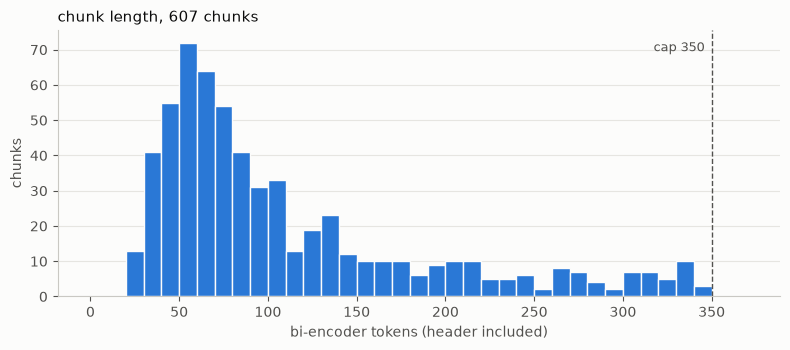

In [12]:
#chunk length, the cap line is where a chunk would start losing text in the bi-encoder (384)
SURFACE, INK, MUTED, SERIES = "#fcfcfb", "#0b0b0b", "#52514e", "#2a78d6"
figure, axis = plt.subplots(figsize=(8, 3.6), facecolor=SURFACE)
axis.set_facecolor(SURFACE)
axis.hist(chunks.n_tokens, bins=range(0, MAX_CHUNK_TOKENS + 25, 10), color=SERIES, edgecolor=SURFACE, linewidth=1)
axis.axvline(MAX_CHUNK_TOKENS, color=MUTED, linestyle="--", linewidth=1)
axis.text(MAX_CHUNK_TOKENS - 4, axis.get_ylim()[1] * 0.92, f"cap {MAX_CHUNK_TOKENS}", ha="right", color=MUTED, fontsize=9)
axis.set_title(f"chunk length, {len(chunks)} chunks", loc="left", color=INK, fontsize=11)
axis.set_xlabel("bi-encoder tokens (header included)", color=MUTED)
axis.set_ylabel("chunks", color=MUTED)
axis.tick_params(colors=MUTED)
axis.grid(axis="y", color="#e6e5e1", linewidth=0.8)
axis.set_axisbelow(True)
for side in ("top", "right"):
    axis.spines[side].set_visible(False)
for side in ("left", "bottom"):
    axis.spines[side].set_color("#c9c8c3")
figure.tight_layout()
figure.savefig(FIGURES / "chunk_tokens.png", dpi=200, facecolor=SURFACE)
plt.show()

a few chunks worth eyeballing: a definition, a rule + its exception, and a recital that covers the same thing as an article

In [13]:
for chunk_id in ("art4.11", "art9.1", "art9.2_p1", "art17.3", "art34.3", "rec85"):
    if chunk_id in set(chunks.chunk_id):
        row = chunks.set_index("chunk_id").loc[chunk_id]
        print(f"--- {chunk_id} | {row.label} | page {row.page} | {row.n_tokens} tokens\n{row.text}\n")

--- art4.11 | Art. 4(11) | page 34 | 74 tokens
Article 4 - Definitions
For the purposes of this Regulation:
(11) ‘consent’ of the data subject means any freely given, specific, informed and unambiguous indication of the data subject's wishes by which he or she, by a statement or by a clear affirmative action, signifies agreement to the processing of personal data relating to him or her;

--- art9.1 | Art. 9(1) | page 38 | 77 tokens
Article 9 - Processing of special categories of personal data
1. Processing of personal data revealing racial or ethnic origin, political opinions, religious or philosophical beliefs, or trade union membership, and the processing of genetic data, biometric data for the purpose of uniquely identifying a natural person, data concerning health or data concerning a natural person's sex life or sexual orientation shall be prohibited.

--- art9.2_p1 | Art. 9(2) part 1/2 | page 38 | 324 tokens
Article 9 - Processing of special categories of personal data
2. Paragra

In [14]:
#save. chunking got frozen at checkpoint a, the hash makes sure nothing about the chunks quietly changes later
CHUNKS_FROZEN_SHA256 = "9efa82c7d031b672023feb77f10a8b8e4a1fb9de3c7bb4c13e78b9d6d90f04bd"  # sha256 over "chunk_id \t text" lines
chunks_sha256 = hashlib.sha256("\n".join(chunks.chunk_id + "\t" + chunks.text).encode("utf-8")).hexdigest()
assert chunks_sha256 == CHUNKS_FROZEN_SHA256, "chunks changed since checkpoint a"

chunks["article"] = chunks.article.astype("Int64")  # recitals have no article, plain int would turn into 17.0
chunks = chunks.drop(columns=["unit", "new_text"])
chunks.to_csv(RESULTS / "chunks.csv", index=False, encoding="utf-8", lineterminator="\n")
RUN_INFO["chunks"] = {"count": len(chunks), "max_tokens": int(chunks.n_tokens.max()), "cap": MAX_CHUNK_TOKENS,
                      "articles": int((chunks.kind == "article").sum()), "recitals": int((chunks.kind == "recital").sum()),
                      "sha256": chunks_sha256}
save_run_info()
print("saved results/chunks.csv | frozen hash ok")

saved results/chunks.csv | frozen hash ok


## bi-encoder index

every chunk -> one 384-dim vector. the model ends in a Normalize layer so vectors are unit length and inner product = cosine.
flat index = exact search over all 607 chunks, no approximation, so a rank is a real rank

In [15]:
def sync() -> None:
    if DEVICE == "cuda":
        torch.cuda.synchronize()  # gpu work is async, without this a timer stops too early


CHUNK_TEXT = dict(zip(chunks.chunk_id, chunks.text))
CHUNK_LABEL = dict(zip(chunks.chunk_id, chunks.label))

started = time.perf_counter()
chunk_vectors = bi_encoder.encode(chunks.text.tolist(), batch_size=64, convert_to_numpy=True).astype("float32")
sync()
index_seconds = time.perf_counter() - started

index = faiss.IndexFlatIP(chunk_vectors.shape[1])
index.add(chunk_vectors)
assert index.ntotal == len(chunks)
assert np.allclose(np.linalg.norm(chunk_vectors, axis=1), 1, atol=1e-4)  # unit length, so the scores below are cosines
RUN_INFO["index"] = {"type": "faiss.IndexFlatIP", "vectors": int(index.ntotal), "dim": int(index.d), "build_seconds": round(index_seconds, 2)}
print(f"indexed {index.ntotal} chunks x {index.d} dims in {index_seconds:.2f}s on {DEVICE} (one-off cost)")

indexed 607 chunks x 384 dims in 3.92s on cuda (one-off cost)


## pipeline 1: baseline

query -> same bi-encoder -> top 10 chunks by cosine. the first 3 go to the llm -> answer 1

In [16]:
def retrieve(query: str, k: int = TOP_K) -> pd.DataFrame:
    query_vector = bi_encoder.encode([query], convert_to_numpy=True).astype("float32")
    scores, positions = index.search(query_vector, k)
    return pd.DataFrame({"chunk_id": chunks.chunk_id.values[positions[0]], "cosine": scores[0], "bi_rank": np.arange(1, k + 1)})


#dev query only, kept out of the eval / stress sets so it can't bias their labels
DEMO_QUERY = "can i take back my consent later, and does that make what they already did with my data illegal?"
retrieve(DEMO_QUERY).assign(label=lambda table: table.chunk_id.map(CHUNK_LABEL))

,chunk_id,cosine,bi_rank,label
0,rec43,0.468825,1,Recital 43
1,art7.1,0.421138,2,Art. 7(1)
2,art7.3,0.408899,3,Art. 7(3)
3,rec33,0.401767,4,Recital 33
4,rec42,0.369570,5,Recital 42
5,art7.2,0.349335,6,Art. 7(2)
6,art7.4,0.347144,7,Art. 7(4)
7,rec32,0.341118,8,Recital 32
8,art8.1,0.331989,9,Art. 8(1)
9,art4.11,0.327042,10,Art. 4(11)


## pipeline 2: rerank

the same 10 candidates, but now each (query, chunk) pair goes through the cross-encoder together, so query words attend to chunk words.
scores are raw logits (Identity activation), only the order matters. ties keep the bi-encoder order.
the first 3 after sorting go to the llm -> answer 2

In [17]:
#longest chunk in cross-encoder tokens, so a query + chunk pair can be checked against the 512 limit without re-tokenizing every pair
CHUNK_CE_TOKENS = {chunk_id: len(cross_encoder.tokenizer(text)["input_ids"]) for chunk_id, text in CHUNK_TEXT.items()}
print("longest chunk in cross-encoder tokens:", max(CHUNK_CE_TOKENS.values()), "| limit", cross_encoder.max_seq_length)


def rerank(query: str, candidates: pd.DataFrame) -> pd.DataFrame:
    query_tokens = len(cross_encoder.tokenizer(query)["input_ids"]) - 1  # pair shares one [CLS]
    longest = query_tokens + max(CHUNK_CE_TOKENS[chunk_id] for chunk_id in candidates.chunk_id)
    assert longest <= cross_encoder.max_seq_length, f"a {longest} token pair would get cut"
    pairs = [(query, CHUNK_TEXT[chunk_id]) for chunk_id in candidates.chunk_id]
    scores = cross_encoder.predict(pairs, batch_size=len(pairs), convert_to_numpy=True)  # all 10 in one batch
    order = candidates.assign(ce_score=scores).sort_values(["ce_score", "bi_rank"], ascending=[False, True], kind="stable")
    order["ce_rank"] = np.arange(1, len(order) + 1)
    assert set(order.chunk_id) == set(candidates.chunk_id)  # reorders the same 10, never adds or drops one
    return order.sort_values("bi_rank").reset_index(drop=True)  # bi order kept, ce_rank says where each one moved


def top_ids(table: pd.DataFrame, rank_column: str) -> list:
    return table.nsmallest(TOP_N, rank_column).chunk_id.tolist()

longest chunk in cross-encoder tokens: 349 | limit 512


## prompt + llm

one prompt builder for both pipelines, so the only thing that differs between answer 1 and answer 2 is which 3 passages go in (and their order).
passages go in rank order, each tagged with its label so the answer can cite it

In [18]:
PROMPT = """You answer questions about the EU GDPR using ONLY the passages below.
Do not use outside knowledge. If the passages do not contain the answer, reply exactly: "Not found in the provided context."
Cite the passage ids you used in square brackets, e.g. [Art. 17(3)].

Passages:
{passages}

Question: {question}
Answer:"""
RUN_INFO["prompt_template"] = PROMPT
LABEL_TO_ID = {label: chunk_id for chunk_id, label in CHUNK_LABEL.items()}


def build_prompt(query: str, chunk_ids: list) -> str:
    passages = "\n\n".join(f"[{CHUNK_LABEL[chunk_id]}]\n{CHUNK_TEXT[chunk_id]}" for chunk_id in chunk_ids)
    return PROMPT.format(passages=passages, question=query)


def cited_ids(answer: str) -> list:
    #"[Art. 17(3)]" or "[Art. 17(1), Recital 65]" -> chunk ids, anything that isn't a real label is ignored
    labels = [label.strip() for group in re.findall(r"\[([^\[\]]+)\]", answer) for label in re.split(r"[;,]\s*(?=Art\.|Recital)", group)]
    return [LABEL_TO_ID[label] for label in labels if label in LABEL_TO_ID]


def generate(prompt: str) -> dict:
    #one fresh user message per call, no chat history
    started = time.perf_counter()
    response = ollama.chat(model=LLM, messages=[{"role": "user", "content": prompt}], options=LLM_OPTIONS, keep_alive="30m")
    wall_ms = (time.perf_counter() - started) * 1000
    answer = response.message.content.strip()
    assert response.prompt_eval_count + LLM_OPTIONS["num_predict"] <= LLM_OPTIONS["num_ctx"], "prompt too long, ollama would cut it"
    return {
        "answer": answer,
        "cited": cited_ids(answer),
        "truncated": response.done_reason == "length",  # stopped at num_predict, judge it as cut off, not as an omission
        "prompt_tokens": response.prompt_eval_count,  # ollama counts only tokens it had to evaluate, a cached prefix is skipped
        "output_tokens": response.eval_count,
        "prefill_ms": response.prompt_eval_duration / 1e6,
        "decode_ms": response.eval_duration / 1e6,
        "load_ms": response.load_duration / 1e6,
        "wall_ms": wall_ms,
    }

In [19]:
#both pipelines end to end for one query
def run_both(query: str, answers: bool = True) -> dict:
    table = rerank(query, retrieve(query))
    result = {"query": query, "table": table, "baseline": top_ids(table, "bi_rank"), "rerank": top_ids(table, "ce_rank")}
    if answers:
        for pipeline in ("baseline", "rerank"):
            result[f"{pipeline}_prompt"] = build_prompt(query, result[pipeline])
            result[f"{pipeline}_answer"] = generate(result[f"{pipeline}_prompt"])
    return result


def show_candidates(table: pd.DataFrame) -> pd.DataFrame:
    view = table.assign(
        label=table.chunk_id.map(CHUNK_LABEL),
        move=table.bi_rank - table.ce_rank,  # positive = the cross-encoder pulled it up
        starts=table.chunk_id.map(lambda chunk_id: CHUNK_TEXT[chunk_id].split("\n", 1)[1][:90]),
    )
    return view[["bi_rank", "ce_rank", "move", "label", "cosine", "ce_score", "starts"]].round(3)

## demo query

a dev example to see everything working, it's not part of the eval set or the stress set

In [20]:
demo = run_both(DEMO_QUERY)
print("baseline top 3:", demo["baseline"], "| rerank top 3:", demo["rerank"])
display(show_candidates(demo["table"]))

baseline top 3: ['rec43', 'art7.1', 'art7.3'] | rerank top 3: ['art7.3', 'rec43', 'rec32']


,bi_rank,ce_rank,move,label,cosine,ce_score,starts
0,1,2,-1,Recital 43,0.469,-2.847,"(43) In order to ensure that consent is freely given, consent should not provide a valid l"
1,2,8,-6,Art. 7(1),0.421,-6.069,"1. Where processing is based on consent, the controller shall be able to demonstrate that"
2,3,1,2,Art. 7(3),0.409,-0.172,3. The data subject shall have the right to withdraw his or her consent at any time. The w
3,4,6,-2,Recital 33,0.402,-4.719,(33) It is often not possible to fully identify the purpose of personal data processing fo
4,5,4,1,Recital 42,0.370,-4.382,"(42) Where processing is based on the data subject's consent, the controller should be abl"
5,6,5,1,Art. 7(2),0.349,-4.468,2. If the data subject's consent is given in the context of a written declaration which al
6,7,9,-2,Art. 7(4),0.347,-6.429,"4. When assessing whether consent is freely given, utmost account shall be taken of whethe"
7,8,3,5,Recital 32,0.341,-3.637,"(32) Consent should be given by a clear affirmative act establishing a freely given, speci"
8,9,10,-1,Art. 8(1),0.332,-7.964,"1. Where point (a) of Article 6(1) applies, in relation to the offer of information societ"
9,10,7,3,Art. 4(11),0.327,-5.433,For the purposes of this Regulation:\n(11) ‘consent’ of the data subject means any freely g


In [21]:
#the exact prompt answer 1 got, answer 2's prompt is the same apart from the passages
print(demo["baseline_prompt"])

You answer questions about the EU GDPR using ONLY the passages below.
Do not use outside knowledge. If the passages do not contain the answer, reply exactly: "Not found in the provided context."
Cite the passage ids you used in square brackets, e.g. [Art. 17(3)].

Passages:
[Recital 43]
Recital 43
(43) In order to ensure that consent is freely given, consent should not provide a valid legal ground for the processing of personal data in a specific case where there is a clear imbalance between the data subject and the controller, in particular where the controller is a public authority and it is therefore unlikely that consent was freely given in all the circumstances of that specific situation. Consent is presumed not to be freely given if it does not allow separate consent to be given to different personal data processing operations despite it being appropriate in the individual case, or if the performance of a contract, including the provision of a service, is dependent on the consent

In [22]:
for pipeline in ("baseline", "rerank"):
    result = demo[f"{pipeline}_answer"]
    print(f"--- answer {1 if pipeline == 'baseline' else 2} ({pipeline} top 3) | cites {result['cited']} | "
          f"{result['prompt_tokens']} prompt tok, {result['output_tokens']} out tok, {result['wall_ms'] / 1000:.1f}s"
          + (" | TRUNCATED" if result["truncated"] else ""))
    print(result["answer"], "\n")

RUN_INFO["llm"]["placement"] = ollama_placement(LLM)  # after real prompts, the model is fully loaded now
save_run_info()

--- answer 1 (baseline top 3) | cites ['art7.3'] | 386 prompt tok, 52 out tok, 2.9s
Yes, [Art. 7(3)] states: "The data subject shall have the right to withdraw his or her consent at any time. The withdrawal of consent shall not affect the lawfulness of processing based on consent before its withdrawal." 

--- answer 2 (rerank top 3) | cites ['art7.3'] | 546 prompt tok, 52 out tok, 3.0s
Yes, [Art. 7(3)] states: "The data subject shall have the right to withdraw his or her consent at any time. The withdrawal of consent shall not affect the lawfulness of processing based on consent before its withdrawal." 

